In [4]:
from langchain_naver import ChatClovaX
import uuid, os, json, asyncio, requests
from typing import Annotated, List, TypedDict, Dict, Optional, Any
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv
from langchain_core.runnables import RunnableConfig
from prompt import *
from task1_funcs import *
from task1_tools import *
from task2_tools import *
from task4_tools import *  
# from task5_tools import *
from utils import *

load_dotenv('/mnt/c/Users/rladl/Desktop/Mirae_Agent/MIRAE_ASSET_AI-Festival/sasha/test/.env')

clova = ChatClovaX(
    api_key=os.getenv('NCP_CLOVASTUDIO_API_KEY'),
    model="HCX-005",
    temperature=0.2,
    max_tokens=None,
    timeout=None,
    # max_retries,
    # repeat_penalt,
    # repetition_penalty,
    # stop,
    # seed,
    # top_k,
    # top_p,
)

# Function Calling 호출 API
API_KEY = os.getenv('NCP_CLOVASTUDIO_API_KEY')
REQUEST_ID = f"req-{uuid.uuid4()}"

url = "https://clovastudio.stream.ntruss.com/testapp/v3/chat-completions/HCX-005"
headers = {
    "Authorization": f"Bearer {API_KEY}",
    "X-NCP-CLOVASTUDIO-REQUEST-ID": REQUEST_ID,
    "Content-Type": "application/json"
}

In [5]:
class ChatbotState(TypedDict):
    question: Annotated[str, "Question"]  
    decision_task: Annotated[str, "Decision_task"]
    tools: Annotated[List, "Tools"]
    tools_response: Annotated[str, "Tools_Response"]

    # 디버깅용 Task1, Task2, Task3, Task4 응답 저장
    task1_response: Annotated[Optional[Dict], "Task2_Response"]
    task2_response: Annotated[Optional[Dict], "Task2_Response"]
    task3_response: Annotated[Optional[Dict], "Task2_Response"]
    task4_response: Annotated[Optional[str], "Task4_Response"]
    task5_response: Annotated[Optional[str], "Task4_Response"]

    answer: Annotated[str, "Final_Answer"]  
    
    # Task5 멀티턴 대응용 필드 (추가)
    session_id: Annotated[Optional[str], "Session_ID"]
    messages: Annotated[List[Dict[str, str]], "Messages"] 

# 메모리 저장소 초기화
memory = MemorySaver()

In [6]:
async def decision_task(state: ChatbotState) -> ChatbotState:
    """
    "Lazy 멀티턴" 구조
    
    LLM이 어떤 Task를 골랐는지 설명을 섞어 출력해도
    'Task1'·'Task2'·'Task3'·'Task4' 형태로 정확히 추출해 state에 저장.
    """
    user_query = state["question"]

    # LLM에게 task 분류 요청
    prompt = TASK_ROUTER_PROMPT.format(question=user_query)
    messages = [("system", prompt)]

    llm_response = await clova.ainvoke(messages)
    raw_text = llm_response.content or ""

    # 1) 공백 제거 및 소문자 정규화
    normalized = re.sub(r"\s+", "", raw_text)

    # 2) 'task' + 숫자 패턴 추출
    m = re.search(r"task\s*([0-9]+)", normalized, re.IGNORECASE)

    # 3) 결과 결정
    decision = f"Task{m.group(1)}" if m else normalized

    # # Task5 진입 시 session_id 생성 + messages 초기화
    # if decision == "Task5":
    #     if not state.get("session_id"):
    #         state["session_id"] = str(uuid.uuid4())

    #     state["messages"] = [{"role": "user", "content": user_query}]

    # 결과 상태 업데이트
    state["decision_task"] = decision
    return state

In [7]:
async def task1_tools(state: ChatbotState):
    user_query = state["question"]

    data = {
    "model": "HCX-005",
    "messages": [
        {"role":"system","content": TOOLS_PROMPT},
        {"role":"user","content": user_query}
    ],
    "tools" : [{"type": "function", "function": s} for s in task1_functions],
    "tool_choice": "auto"
    }

    response = requests.post(url, headers=headers, json=data)
    result = response.json()

    tool_calls = result['result']['message']['toolCalls']

    for call in tool_calls:
        fn_name = call["function"]["name"]
        args    = call["function"]["arguments"]     # dict 또는 JSON 문자열
        if isinstance(args, str):
            args = json.loads(args)

        py_func = task1_py_funcs.get(fn_name)
        if py_func is None:
            raise ValueError(f"Unsupported function: {fn_name}")

        # 동기/비동기 모두 지원
        if asyncio.iscoroutinefunction(py_func):
            out = await py_func(**args)
        else:
            out = await asyncio.to_thread(py_func, **args)

    return ChatbotState(tools=result,
                        tools_response=out)


In [8]:
async def task2_tools(state: ChatbotState):
    user_query = state["question"]

    # 1. 모델 응답
    messages = [("system", TASK2_PROMPT),("human", user_query)]
    ai_msg = clova.invoke(messages)

    # 2. 응답 전처리
    llm_question_analysis = parse_llm_json(ai_msg.content)

    # 3. 최종 응답
    result = screen_stocks(llm_question_analysis)
    
    return ChatbotState(task2_response=result)


In [9]:
async def task3_tools(state: ChatbotState):
    user_query = state["question"]

    data = {
    "model": "HCX-005",
    "messages": [
        {"role":"user","content": user_query}
    ],
    "tools" : [{"type": "function", "function": s} for s in task1_functions],
    "tool_choice": "auto"
    }

    response = requests.post(url, headers=headers, json=data)
    result = response.json()

    return ChatbotState(tools=result)


In [10]:
async def task4_tools(state: ChatbotState):
    """
    Task4: 모호한 의미 해석 및 재질의 처리
    """
    user_query = state["question"]

    prompt = TASK4_FINAL_PROMPT.format(
        question=user_query
    )

    data = {
        "model": "HCX-005",
        "messages": [
            {"role": "system", "content": prompt},
            {"role": "user", "content": user_query}
        ]
    }

    response = requests.post(url, headers=headers, json=data)
    content = response.json()["result"]["message"]["content"]

    return ChatbotState(
        question=user_query,
        decision_task="Task4",
        task4_response=content,
        answer=content
    )

In [11]:
class Task5ChatbotState:
    """Task5용 간소화된 State 클래스"""
    def __init__(self, question: str = "", task5_response: str = ""):
        self.question = question
        self.task5_response = task5_response

In [12]:
async def task5_tools(state: Task5ChatbotState):
    """
    Task5 LangGraph 노드: Fin문철의 블랙박스 투자 분석 도구
    
    Args:
        state: ChatbotState 객체 (question 포함)
    
    Returns:
        ChatbotState 객체 (task5_response 업데이트)
    """
    
    user_query = state.question
    
    try:
        # 1. 질문 의도 분석
        intent = detect_query_intent(user_query)
        print(f"감지된 질문 의도: {intent}")
        
        # 2. 종목명 추출
        company_name = extract_company_name_from_query(user_query)
        print(f"추출된 종목명: {company_name}")
        
        if not company_name:
            # 종목명이 없는 경우 재질문
            result = """
❓ **종목명을 찾을 수 없습니다**

투자 분석을 위해서는 구체적인 종목명이 필요합니다.

**예시 질문:**
- "삼성전자 작년에 매수한 판단 어때?"
- "애플 지금 사도 될까?"
- "테슬라 300달러에 산 투자 심사해줘"

어떤 종목을 분석해드릴까요?

더 궁금하신가요?
"""
            return Task5ChatbotState(question=user_query, task5_response=result)
        
        # 3. 의도별 함수 호출
        if intent == "past_analysis":
            # 과거 투자 분석 - 날짜와 가격 추출 시도
            purchase_info = _extract_purchase_info(user_query)
            
            if not purchase_info.get("date"):
                result = f"""
📅 **매수 시점 정보가 필요합니다**

'{company_name}'의 투자 분석을 위해 매수 날짜를 알려주세요.

**예시:**
- "삼성전자 2023년 5월에 매수한 판단 어때?"
- "애플 작년 12월 15일에 산 거 분석해줘"

언제 매수하셨나요?

더 궁금하신가요?
"""
                return Task5ChatbotState(question=user_query, task5_response=result)
            
            # 과거 투자 분석 실행
            result = analyze_investment_decision(
                stock_name=company_name,
                purchase_date=purchase_info["date"],
                purchase_price=purchase_info.get("price")
            )
            
        elif intent == "current_analysis":
            # 현재 투자 가치 분석
            result = check_current_investment_worthiness(stock_name=company_name)
            
        elif intent == "verdict_request":
            # AI 판결 시스템 - 상세 정보 필요
            purchase_info = _extract_purchase_info(user_query)
            
            if not purchase_info.get("date") or not purchase_info.get("price"):
                result = f"""
⚖️ **판결을 위한 상세 정보가 필요합니다**

'{company_name}'에 대한 AI 판결을 위해 다음 정보를 알려주세요:
- 매수 날짜
- 매수 가격

**예시:**
- "삼성전자 2023년 7월 15일에 75,000원에 산 투자 판결해줘"

정확한 매수 정보를 알려주시면 전문적인 판결문을 작성해드리겠습니다.

더 궁금하신가요?
"""
                return Task5ChatbotState(question=user_query, task5_response=result)
            
            # AI 판결 시스템 실행
            result = generate_investment_verdict(
                stock_name=company_name,
                purchase_date=purchase_info["date"],
                purchase_price=purchase_info["price"]
            )
            
        else:
            # 일반적인 투자 문의 - 현재 분석으로 처리
            result = check_current_investment_worthiness(stock_name=company_name)
        
        return Task5ChatbotState(question=user_query, task5_response=result)
        
    except Exception as e:
        error_result = f"""
❌ **분석 중 오류가 발생했습니다**

오류 내용: {str(e)}

다시 한번 시도해주시거나, 다음과 같이 질문해주세요:
- "종목명 + 구체적인 분석 요청"
- 예: "삼성전자 현재 투자 가치 분석해줘"

더 궁금하신가요?
"""
        return Task5ChatbotState(question=user_query, task5_response=error_result)


def _extract_purchase_info(query: str) -> Dict[str, Any]:
    """질문에서 매수 날짜와 가격 정보 추출"""
    
    purchase_info = {"date": None, "price": None}
    
    # 날짜 패턴 매칭
    date_patterns = [
        r'(\d{4})년\s*(\d{1,2})월\s*(\d{1,2})일?',  # 2023년 5월 15일
        r'(\d{4})-(\d{1,2})-(\d{1,2})',           # 2023-05-15
        r'(\d{4})\.(\d{1,2})\.(\d{1,2})',         # 2023.05.15
        r'작년\s*(\d{1,2})월\s*(\d{1,2})일?',      # 작년 5월 15일
        r'올해\s*(\d{1,2})월\s*(\d{1,2})일?',      # 올해 5월 15일
    ]
    
    for pattern in date_patterns:
        match = re.search(pattern, query)
        if match:
            groups = match.groups()
            
            if pattern.startswith(r'작년'):
                # 작년 처리
                current_year = datetime.now().year
                year = current_year - 1
                month, day = groups
                purchase_info["date"] = f"{year}-{month.zfill(2)}-{day.zfill(2)}"
            elif pattern.startswith(r'올해'):
                # 올해 처리
                current_year = datetime.now().year
                month, day = groups
                purchase_info["date"] = f"{current_year}-{month.zfill(2)}-{day.zfill(2)}"
            else:
                # 일반적인 날짜 형식
                year, month, day = groups
                purchase_info["date"] = f"{year}-{month.zfill(2)}-{day.zfill(2)}"
            break
    
    # 가격 패턴 매칭
    price_patterns = [
        r'(\d{1,3}(?:,\d{3})*)\s*원',           # 75,000원
        r'(\d+(?:\.\d+)?)\s*달러',               # 150달러, 150.5달러
        r'(\d{1,3}(?:,\d{3})*)\s*만원',         # 7만원 -> 70,000원으로 변환
        r'(\d+)\s*만\s*(\d+)',                  # 7만 5천 -> 75,000원
    ]
    
    for pattern in price_patterns:
        match = re.search(pattern, query)
        if match:
            if '만원' in pattern:
                # 만원 단위 처리
                amount = int(match.group(1).replace(',', ''))
                purchase_info["price"] = amount * 10000
            elif '만' in pattern and '달러' not in pattern:
                # "7만 5천" 형태 처리
                man, thousand = match.groups()
                purchase_info["price"] = int(man) * 10000 + int(thousand) * 1000
            else:
                # 일반적인 가격
                price_str = match.group(1).replace(',', '')
                purchase_info["price"] = float(price_str)
            break
    
    return purchase_info


def _validate_stock_name(stock_name: str) -> bool:
    """종목명 유효성 검사"""
    if not stock_name:
        return False
    
    # 최소 길이 체크
    if len(stock_name) < 2:
        return False
    
    # 한글 또는 영문으로 구성되어야 함
    if not (re.match(r'^[가-힣]+', stock_name) or re.match(r'^[A-Za-z]+', stock_name)):
        return False
    
    return True


def _format_analysis_result(raw_result: str, query_type: str) -> str:
    """분석 결과 포맷팅"""
    
    if raw_result.startswith("❌"):
        return raw_result
    
    # 결과 타입별 헤더 추가
    headers = {
        "past_analysis": "📊 **투자 블랙박스 분석 결과**",
        "current_analysis": "📈 **현재 투자 가치 진단**", 
        "verdict_request": "⚖️ **AI 투자 판결문**"
    }
    
    header = headers.get(query_type, "📋 **투자 분석 결과**")
    
    # 이미 헤더가 있는 경우 중복 제거
    if any(h in raw_result for h in headers.values()):
        return raw_result
    
    return f"{header}\n\n{raw_result}"

In [ ]:
# async def task5_tools(state: ChatbotState) -> ChatbotState:
#     """
#     Task5: 멀티턴 처리 – 이전 messages context 포함 + HCX Function Calling 처리
#     """
#     messages = state.get("messages", [])
#     user_input = state["question"]

#     # messages에 이번 질문 추가
#     messages.append({"role": "user", "content": user_input})

#     data = {
#         "model": "HCX-005",
#         "messages": messages,
#         "tools": [{"type": "function", "function": f} for f in task5_functions],
#         "tool_choice": "auto"
#     }

#     response = requests.post(url, headers=headers, json=data)
#     result = response.json()

#     tool_calls = result["result"]["message"].get("toolCalls", [])
#     final_output = ""

#     for call in tool_calls:
#         fn_name = call["function"]["name"]
#         args = call["function"]["arguments"]
#         if isinstance(args, str):
#             args = json.loads(args)

#         py_func = task5_py_funcs.get(fn_name)
#         if py_func is None:
#             raise ValueError(f"Unsupported function: {fn_name}")

#         if asyncio.iscoroutinefunction(py_func):
#             out = await py_func(**args)
#         else:
#             out = await asyncio.to_thread(py_func, **args)

#         final_output = out

#     # HCX 응답 메시지도 추가
#     messages.append({
#         "role": "assistant",
#         "content": final_output
#     })

#     return ChatbotState(
#         question=user_input,
#         session_id=state.get("session_id"),
#         messages=messages,
#         answer=final_output
#     )


In [14]:
# # 아주 간단한 메모리 기반 세션 저장소 (배포 시 Redis로 교체 가능)
# _session_memory = {}

# def load_session(session_id: str) -> list:
#     """session_id에 해당하는 메시지 기록을 불러옴"""
#     return _session_memory.get(session_id, [])

# def save_session(session_id: str, messages: list):
#     """session_id에 해당하는 메시지를 저장"""
#     _session_memory[session_id] = messages

In [15]:
async def agent_answer(state: ChatbotState):
    user_query = state["question"]
    tool = state['tools']
    decision_task = state['decision_task']
    task2_res = state['task2_response']
    task4_res = state.get('task4_response', '')  # Task4 응답 추가

    if decision_task == 'Task1':
        prompt = ANSWER_PROMPT.format(question=user_query, 
                                      tool_result=tool)
        messages = [("system", prompt)]
        llm_resp = await clova.ainvoke(messages)
        answer = llm_resp.content.strip()

    elif decision_task == 'Task2':
        prompt = TASK2_FINAL_PROMPT.format(question=user_query,
                                           tool_result=task2_res)
        messages = [("system", prompt)]
        llm_resp = await clova.ainvoke(messages)
        answer = llm_resp.content.strip()

    elif decision_task == 'Task3':
        prompt = ANSWER_PROMPT.format(question=user_query, 
                                      tool_result=tool)
        messages = [("system", prompt)]
        llm_resp = await clova.ainvoke(messages)
        answer = llm_resp.content.strip()

    elif decision_task == 'Task4':
        prompt = TASK4_FINAL_PROMPT.format(question=user_query,
                                           tool_result=task4_res)
        messages = [("system", prompt)]
        llm_resp = await clova.ainvoke(messages)
        answer = llm_resp.content.strip()

    elif decision_task == 'Task5':
        prompt = TASK5_FINAL_PROMPT.format(question=user_query,
                                            tool_result=task4_res)
        messages = [("system", prompt)]
        llm_resp = await clova.ainvoke(messages)
        answer = llm_resp.content.strip()

    else:
        answer = "죄송합니다. 질문을 이해하지 못했습니다. 다시 한번 구체적으로 질문해 주세요."

    return ChatbotState(answer=answer,
                        messages=[("user", user_query), ("assistant", answer)])

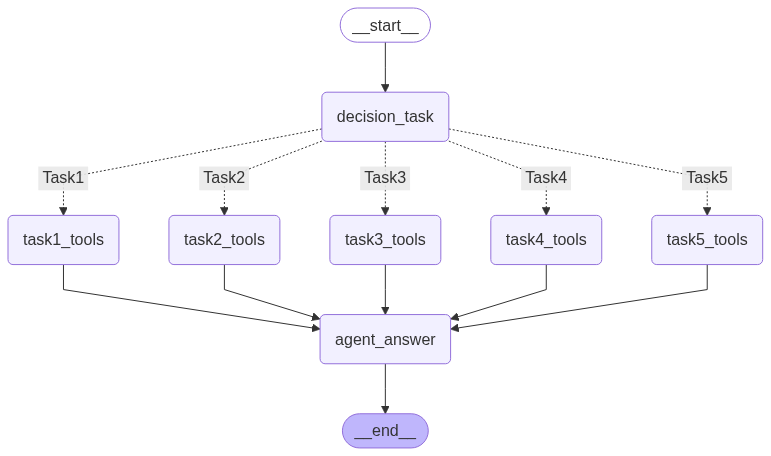

In [18]:
def route_tools(state: ChatbotState):
    return state["decision_task"]

# StateGraph 구성
builder = StateGraph(ChatbotState)

builder.add_node("decision_task", decision_task)

builder.add_node("task1_tools", task1_tools)
builder.add_node("task2_tools", task2_tools)
builder.add_node("task3_tools", task3_tools)
builder.add_node("task4_tools", task4_tools) # Task4 노드 추가
builder.add_node("task5_tools", task5_tools) # Task4 노드 추가
builder.add_node("agent_answer", agent_answer)

builder.add_edge(START, "decision_task")

builder.add_conditional_edges(
    "decision_task",
    route_tools,
    {
        "Task1": "task1_tools",
        "Task2": "task2_tools",
        "Task3": "task3_tools",
        "Task4": "task4_tools",
        "Task5": "task5_tools"
    }
)
builder.add_edge("task1_tools", "agent_answer")
builder.add_edge("task2_tools", "agent_answer")
builder.add_edge("task3_tools", "agent_answer")
builder.add_edge("task4_tools", "agent_answer")  # Task4 엣지 추가
builder.add_edge("task5_tools", "agent_answer")  # Task4 엣지 추가
builder.add_edge("agent_answer", END)

builder.compile(checkpointer=memory)

In [ ]:
# Jupyter 노트북에서 실행할 셀들

# ============================================================================
# 1. Task4 테스트 실행
# ============================================================================

async def test_task4():
    """Task4 기능을 테스트하는 함수"""
    config = RunnableConfig(configurable={"thread_id": 4}) # 실행 환경 설정
    graph = builder.compile(checkpointer=memory) 
    
    # 모호한 질문 테스트
    test_cases = [
      # 1. 시간 기준 모호성 (시간점 불명)

        "수익봤으면 언제 팔아야돼?",
        "최근 많이 오른 주식을 알려줘",
        "고점 대비 많이 떨어진 주식을 보여줘",
        "요즘 급등한 종목이 뭐야?",
        "근래에 좋은 실적 발표한 회사 어디야?",
        "얼마전에 터진 악재 종목 알려줘",
        "올해 들어 많이 상승한 주식은?",
        "최근 급락한 종목을 찾아줘",
        "지금까지 수익률이 좋았던 주식은?",
        "작년 대비 많이 오른 종목 추천해줘",

        #2. 정량 기준 모호성 (수치/비율 불명)

        "상승률이 높은 주식을 보여줘",
        "거래량이 급증한 종목 알려줘",
        "PER이 낮은 저평가 주식 추천해줘",
        "배당률이 좋은 종목이 뭐야?",
        "시가총액이 큰 대형주를 알려줘",
        "변동성이 큰 종목 찾아줘",
        "수익률이 높은 펀드 추천해줘",
        "손실 폭이 큰 종목을 보여줘",
        "거래대금이 많은 인기 종목은?",
        "부채비율이 낮은 안전한 주식은?"
    ]
    
    
    for question in test_cases:
        print(f"\n{'='*50}")
        print(f"질문: {question}")
        print('='*50)
        
        # Chatstate 초기화 
        initial_state = { 
            "question": question,
            "decision_task": "",
            "tools": [],
            "tools_response": "",
            "task2_response": {},
            "task4_response": "",
            "answer": "", # 최종 답변
            "messages": [], # 멀티턴 대화를 위한 message 히스토리
        }
        
        events = [] # Agent 실행과정에서의 중간 이벤트 저장
        async for event in graph.astream(initial_state, config=config):
            events.append(event)
            
        # 결과 출력
        for event in events:
            if "decision_task" in event:
                print(f"🔍 분류: {event['decision_task']['decision_task']}")
            elif "agent_answer" in event and "answer" in event["agent_answer"]:
                print(f"💬 답변:\n{event['agent_answer']['answer']}")

# 실행
await test_task4()


질문: 수익봤으면 언제 팔아야돼?
🔍 분류: Task4
💬 답변:
수익을 본 주식을 언제 팔아야 할지 결정하기 위해서는 몇 가지 고려 사항이 필요합니다. 다음 중 어떤 상황에 해당하시는지 구체적으로 말씀해주시면 보다 정확한 조언을 드릴 수 있습니다.

1. **단기 투자**: 최근 매수한 주식의 수익 실현 시점을 알고 싶으신가요? 예를 들어, "최근 한 달간 산 주식들의 현재 수익률과 매도 시점 추천"처럼 기간을 명시해 주세요.
   
2. **장기 투자**: 장기적인 관점에서 특정 주식의 목표 수익률을 달성했을 때 매도 여부를 알고 싶으시면, "현재 보유한 A주식의 목표 수익률은 XX%"와 같이 알려주세요.

3. **전반적인 전략 문의**: 일반적인 주식 매도 타이밍 전략을 알고 싶으시면, 이에 대해서도 도움을 드릴 수 있습니다.

어떤 상황인지 구체적으로 말씀해 주시면, 그에 맞는 답변을 제공해 드리겠습니다. 더 궁금하신가요?

질문: 최근 많이 오른 주식을 알려줘
🔍 분류: Task4
💬 답변:
"최근"이라는 기간은 주관적일 수 있으므로, 기간을 명확히 정해주셔야 합니다. 예를 들어 최근 1개월, 3개월 혹은 6개월 등의 기간을 말씀해주시면 해당 기간 동안 많이 오른 주식을 찾아드릴 수 있습니다. 또한, 특정 시장(예: 코스피, 코스닥)이나 업종(예: IT, 바이오 등)의 주식만을 원하시는지도 알려주시면 더욱 정확한 정보를 제공해 드릴 수 있습니다.

아래와 같이 질문해 주세요:
1. 최근 1개월간 가장 많이 오른 주식 리스트는 어떻게 되나요?
2. 최근 3개월간 코스피 시장에서 상승률이 높은 상위 5개의 종목은 무엇인가요?

원하시는 기간을 말씀해 주시면 그에 맞춰서 자세히 설명드리겠습니다. 더 궁금하신가요?

질문: 고점 대비 많이 떨어진 주식을 보여줘
🔍 분류: Task4
💬 답변:
고점을 기준으로 얼마나 떨어졌는지 확인하려면 특정 기간과 고점의 기준이 필요합니다. 예를 들어 최근 6개월 동안의 최고점과 비교하여 현재 가격이 하락한 정도를 알고 


9 Failed downloads:
['456040.KS', '465770.KS', '017860.KS', '487570.KS', '415640.KS', '443060.KS', '499790.KS', '475150.KS', '064400.KS']: YFPricesMissingError('possibly delisted; no price data found  (1d 2023-05-10 00:00:00 -> 2023-05-16 00:00:00) (Yahoo error = "Data doesn\'t exist for startDate = 1683644400, endDate = 1684162800")')


✓ Batch 1 completed
Processing batch 2/14 (200 tickers)



7 Failed downloads:
['454910.KS', '475560.KS', '460860.KS', '092790.KS', '483650.KS', '460850.KS', '111380.KS']: YFPricesMissingError('possibly delisted; no price data found  (1d 2023-05-10 00:00:00 -> 2023-05-16 00:00:00) (Yahoo error = "Data doesn\'t exist for startDate = 1683644400, endDate = 1684162800")')


✓ Batch 2 completed
Processing batch 3/14 (200 tickers)



5 Failed downloads:
['062040.KS', '462870.KS', '031210.KS', '480370.KS', '481850.KS']: YFPricesMissingError('possibly delisted; no price data found  (1d 2023-05-10 00:00:00 -> 2023-05-16 00:00:00) (Yahoo error = "Data doesn\'t exist for startDate = 1683644400, endDate = 1684162800")')


... (63 outputs left out)


6 Failed downloads:
['056730.KQ', '440290.KQ', '418620.KQ', '477760.KQ', '489790.KS']: YFPricesMissingError('possibly delisted; no price data found  (1d 2023-05-10 00:00:00 -> 2023-05-16 00:00:00) (Yahoo error = "Data doesn\'t exist for startDate = 1683644400, endDate = 1684162800")')
['099520.KQ']: YFTzMissingError('possibly delisted; no timezone found')


✓ Batch 5 completed
Processing batch 6/14 (200 tickers)



25 Failed downloads:
['402490.KQ', '464680.KQ', '474610.KQ', '420770.KQ', '145170.KQ', '459510.KQ', '455250.KQ', '482520.KQ', '473980.KQ', '418470.KQ', '389650.KQ', '478390.KQ', '417200.KQ', '489210.KQ', '465320.KQ', '453450.KQ', '405920.KQ', '469480.KQ', '476470.KQ', '492220.KQ', '486630.KQ', '456490.KQ', '476080.KQ', '467930.KQ']: YFPricesMissingError('possibly delisted; no price data found  (1d 2023-05-10 00:00:00 -> 2023-05-16 00:00:00) (Yahoo error = "Data doesn\'t exist for startDate = 1683644400, endDate = 1684162800")')
['293580.KQ']: YFPricesMissingError('possibly delisted; no price data found  (1d 2023-05-10 00:00:00 -> 2023-05-16 00:00:00)')


✓ Batch 6 completed
Processing batch 7/14 (200 tickers)


In [ ]:
# ============================================================================
# 3. 단일 질문 테스트 함수
# ============================================================================

async def test_single_question(question: str):
    """단일 질문을 테스트하는 함수"""
    config = RunnableConfig(configurable={"thread_id": 1})
    graph = builder.compile(checkpointer=memory)
    
    print(f"질문: {question}")
    print('='*50)
    
    initial_state = {
        "question": question,
        "decision_task": "",
        "tools": [],
        "tools_response": "",
        "task2_response": {},
        "task4_response": "",
        
        "messages": [],
    }
    
    events = []
    async for event in graph.astream(initial_state, config=config):
        events.append(event)
        
    # 결과 출력
    for event in events:
        if "decision_task" in event:
            print(f"🔍 분류: {event['decision_task']['decision_task']}")
        elif "agent_answer" in event and "answer" in event["agent_answer"]:
            print(f"💬 답변:\n{event['agent_answer']['answer']}")


await test_single_question("고점 대비 떨어진 주식을 보여줘")


질문: 고점 대비 떨어진 주식을 보여줘
🔍 분류: Task4
💬 답변:
고점 대비 떨어진 주식을 확인하기 위해서는 특정 기간의 정보가 필요합니다. 아래에서 원하는 기간을 선택해 주세요:

1. 최근 1주일 (7일)
2. 최근 1개월 (30일)
3. 최근 3개월 (90일)
4. 최근 6개월 (180일)
5. 최근 1년 (252일)

또는 "YYYY-MM-DD부터 YYYY-MM-DD까지" 형식으로 직접 기간을 지정할 수도 있습니다.

예시: "최근 30일간 고점 대비 하락한 주식을 보여줘" 또는 "2024-01-01부터 2024-06-30까지 고점에서 가장 많이 떨어진 주식"

원하는 기간을 말씀해주시면 해당 조건에 맞는 주식 목록을 제공해드리겠습니다. 더 궁금하신가요?


In [ ]:
config = RunnableConfig(configurable={"thread_id": 1})

question = "2025-06-27에서 KOSPI에서 거래량 많은 종목 10개는?"

graph = builder.compile(checkpointer=memory)

initial_state = {
    "question": question,
    "decision_task":"",
    "tools": [],
    "tools_response" : [],
    "task2_response " : {},
    "answer": "",
    "messages": [],
} 

events = []
async for event in graph.astream(initial_state,config=config):
    print(event)
    events.append(event)

{'decision_task': {'decision_task': 'Task1'}}


/mnt/c/Users/rladl/Desktop/Mirae_Agent/MIRAE_ASSET_AI-Festival/sasha/test/task1_tools.py:97: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(

6 Failed downloads:
['139050.KQ', '226360.KQ', '111870.KQ']: YFPricesMissingError('possibly delisted; no price data found  (1d 2025-06-27 -> 2025-06-28)')
['415640.KQ', '499790.KQ', '487570.KQ']: YFTzMissingError('possibly delisted; no timezone found')
/mnt/c/Users/rladl/Desktop/Mirae_Agent/MIRAE_ASSET_AI-Festival/sasha/test/task1_tools.py:97: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(

2 Failed downloads:
['100090.KQ']: YFTzMissingError('possibly delisted; no timezone found')
['950110.KQ']: YFPricesMissingError('possibly delisted; no price data found  (1d 2025-06-27 -> 2025-06-28)')
/mnt/c/Users/rladl/Desktop/Mirae_Agent/MIRAE_ASSET_AI-Festival/sasha/test/task1_tools.py:97: FutureWarning: YF.download() has changed argument auto_adjust default